# Experiment 26: Gibbs Sampling and Contrastive Divergence Analysis

The streaming team asks how many Gibbs steps justify their extra compute. We compare CD-1, CD-5, CD-10 and persistent CD on the same small binary pattern data, track reconstruction/pseudo-log-likelihood and inspect Gibbs-chain samples.

**Tools:** NumPy, SciPy, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Implement alternating visible/hidden block Gibbs sampling.  2. Display samples after 1, 10, 100 and 1000 steps.  3. Train RBMs with CD-1, CD-5, CD-10 and PCD.  4. Plot reconstruction error and pseudo-log-likelihood.  5. Compare training time and sample quality.

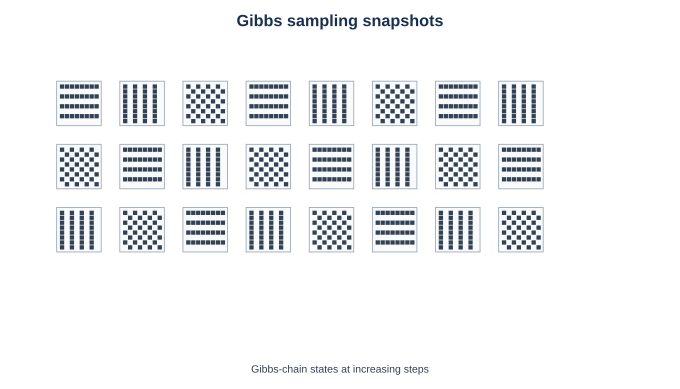

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.special import expit

rng=np.random.default_rng(26)
Vdata=np.zeros((240,64))
for i in range(len(Vdata)):
    im=np.zeros((8,8));k=i%4
    if k==0:im[2:6,:]=1
    elif k==1:im[:,2:6]=1
    elif k==2:np.fill_diagonal(im,1);np.fill_diagonal(np.fliplr(im),1)
    else:im[2:6,2:6]=1
    Vdata[i]=(rng.random(64)<np.clip(im.ravel()+rng.normal(0,.1,64),0,1))
def train_rbm(k,epochs=18,persistent=False):
    W=rng.normal(0,.02,(64,20));a=np.zeros(64);b=np.zeros(20);chain=(rng.random((24,64))<.5).astype(float)
    errors=[];pll=[];start=time.perf_counter()
    def ph(v):return expit(v@W+b)
    def pv(h):return expit(h@W.T+a)
    def free(v):return -v@a-np.logaddexp(0,v@W+b).sum(axis=1)
    for ep in range(epochs):
        for s in range(0,len(Vdata),24):
            v0=Vdata[s:s+24];pos=ph(v0)
            if persistent:
                v=chain[:len(v0)]
            else:v=v0.copy()
            for _ in range(k):
                h=(rng.random(ph(v).shape)<ph(v)).astype(float)
                pv1=pv(h);v=(rng.random(pv1.shape)<pv1).astype(float)
            neg=ph(v)
            W+=.03*(v0.T@pos-v.T@neg)/len(v0)
            a+=.03*np.mean(v0-v,axis=0);b+=.03*np.mean(pos-neg,axis=0)
            if persistent:chain[:len(v0)]=v
        rec=pv(ph(Vdata));errors.append(np.mean((Vdata-rec)**2))
        # Mean pseudo-log-likelihood approximation from a random single-bit flip.
        idx=rng.integers(0,len(Vdata));bit=rng.integers(0,64);flipped=Vdata[idx:idx+1].copy();flipped[0,bit]=1-flipped[0,bit]
        delta=free(flipped)[0]-free(Vdata[idx:idx+1])[0]
        pll.append(64*(-np.logaddexp(0,-delta)))
    return W,a,b,errors,pll,time.perf_counter()-start
models={}
for name,k,pcd in [("CD-1",1,False),("CD-5",5,False),("CD-10",10,False),("PCD-5",5,True)]:
    models[name]=train_rbm(k,persistent=pcd)
    print(name,"seconds",round(models[name][-1],2),"final reconstruction",round(models[name][3][-1],4))
steps=[1,10,100,1000]
W,a,b,*_=models["CD-5"]
def gibbs(v,steps):
    for _ in range(steps):
        h=(rng.random(expit(v@W+b).shape)<expit(v@W+b)).astype(float)
        pv=expit(h@W.T+a);v=(rng.random(pv.shape)<pv).astype(float)
    return v
seed=(rng.random((1,64))<.5).astype(float)
fig,axes=plt.subplots(1,4,figsize=(8,2))
for ax,nstep in zip(axes,steps):
    sample=gibbs(seed.copy(),nstep)[0].reshape(8,8)
    ax.imshow(sample,cmap="gray");ax.set_title(f"{nstep} Gibbs steps");ax.axis("off")
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,4))
for name,result in models.items():
    axes[0].plot(result[3],label=name);axes[1].plot(result[4],label=name)
axes[0].set(title="Reconstruction MSE",xlabel="Epoch")
axes[1].set(title="Pseudo-log-likelihood estimate",xlabel="Epoch")
for ax in axes:ax.grid(alpha=.2);ax.legend(fontsize=8)
plt.tight_layout();plt.show()